In [16]:
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q2_a_b_c.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [17]:
class CIFAR10Subset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


class MLPRegularized(nn.Module):
    def __init__(self, dropout_p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.net(x)


class ConvNetMatched(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048, 150),
            nn.ReLU(),
            nn.Linear(150, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [18]:
def get_raw_splits(seed=260007, data_dir="./data"):
    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train, y_train = all_images[train_idx], all_labels[train_idx]
    X_val, y_val = all_images[val_idx], all_labels[val_idx]
    X_test, y_test = raw_test.data, np.array(raw_test.targets)

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    return (X_train, y_train), (X_val, y_val), (X_test, y_test), mean, std, raw_train.classes

def build_loaders(train_data, val_data, test_data, transform, seed=260007, batch_size=1024):
    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = DataLoader(
        CIFAR10Subset(*train_data, transform=transform),
        batch_size=batch_size, shuffle=True, num_workers=2, generator=g
    )
    val_loader = DataLoader(
        CIFAR10Subset(*val_data, transform=transform),
        batch_size=256, shuffle=False, num_workers=2
    )
    test_loader = DataLoader(
        CIFAR10Subset(*test_data, transform=transform),
        batch_size=256, shuffle=False, num_workers=2
    )
    return train_loader, val_loader, test_loader


class FixedSpatialPermutation:
    def __init__(self, seed=260007):
        rng = np.random.default_rng(seed)
        self.perm = torch.from_numpy(rng.permutation(32 * 32)).long()

    def __call__(self, tensor_img):
        c, h, w = tensor_img.shape
        flat = tensor_img.view(c, h * w)
        return flat[:, self.perm].view(c, h, w)

In [19]:
def train_model(model, train_loader, val_loader, epochs=30, lr=1e-3, weight_decay=1e-4, device="cpu"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for _ in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(dim=1) == y).sum().item()
                total += y.size(0)
        val_acc = 100.0 * correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return model, best_val_acc


def evaluate_detailed(model, loader, device="cpu"):
    model.eval()
    all_preds, all_labels, all_confs = [], [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            probs = torch.softmax(model(x), dim=1)
            confs, preds = probs.max(dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(y.numpy())
            all_confs.append(confs.cpu().numpy())

    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    confs = np.concatenate(all_confs)
    acc = 100.0 * np.mean(preds == labels)
    return acc, preds, labels, confs

In [20]:
def plot_q2_deliverables(clean_stats, perm_stats, gray_stats, classes, save_path="q2_confidence_error_analysis.png"):
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

    conditions = ["Clean RGB\n(Part a)", "Pixel-Permuted\n(Part b)", "Grayscale\n(Part c)"]
    stats_list = [clean_stats, perm_stats, gray_stats]

    correct_confs = [s["confs"][s["preds"] == s["labels"]].mean() * 100 for s in stats_list]
    wrong_confs = [s["confs"][s["preds"] != s["labels"]].mean() * 100 for s in stats_list]

    x = np.arange(len(conditions))
    width = 0.35
    bars1 = axes[0].bar(x - width / 2, correct_confs, width, label="Correct Predictions", color="#1b9e77")
    bars2 = axes[0].bar(x + width / 2, wrong_confs, width, label="Misclassified (Errors)", color="#d95f02")

    for bar in bars1:
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
                     f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9)
    for bar in bars2:
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
                     f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9)

    axes[0].set_title("ConvNet-Matched Test Confidence: Correct vs. Errors")
    axes[0].set_ylabel("Mean Max-Softmax Confidence (%)")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(conditions)
    axes[0].set_ylim(0, 108)
    axes[0].grid(True, axis="y", alpha=0.3)
    axes[0].legend(loc="lower right")

    clean_err = [100.0 * np.mean(clean_stats["preds"][clean_stats["labels"] == c] != c) for c in range(10)]
    gray_err = [100.0 * np.mean(gray_stats["preds"][gray_stats["labels"] == c] != c) for c in range(10)]
    err_increase = [gray_err[c] - clean_err[c] for c in range(10)]

    order = np.argsort(err_increase)[::-1]
    sorted_classes = [classes[i] for i in order]
    sorted_inc = [err_increase[i] for i in order]

    axes[1].barh(sorted_classes[::-1], sorted_inc[::-1], color="#7570b3")
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title("Per-Class Test Error Rate Increase Without Colour (Grayscale - Clean)")
    axes[1].set_xlabel("Error Rate Increase (Percentage Points)")
    axes[1].grid(True, axis="x", alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

Running Question 2 on device: cuda

Training Part (b): Spatially Permuted MLP and CNN...
Training Part (c): Grayscale CNN & MLP...

Model              |    Params |  Clean (a) | Permuted (b) | Grayscale (c)
----------------------------------------------------------------------------
MLP-Regularized    |   402,634 |     54.04% |       53.93% |        44.59%
ConvNet-Matched    |   402,556 |     75.22% |       51.22% |        72.57%

--- ConvNet-Matched Mean Max-Softmax Confidence (Test Set) ---
Clean RGB (a) | Correct Preds: 87.47% | Misclassified (Errors): 65.50%
Permuted  (b) | Correct Preds: 70.53% | Misclassified (Errors): 53.45%
Grayscale (c) | Correct Preds: 87.00% | Misclassified (Errors): 64.63%


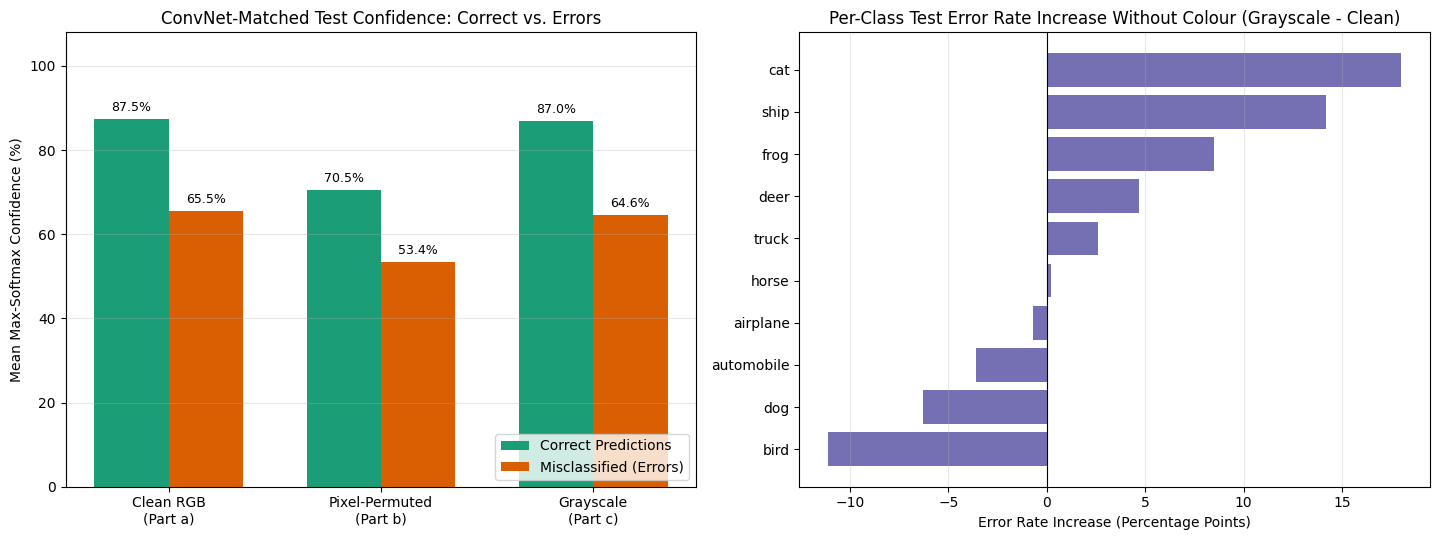

In [21]:
if __name__ == "__main__":
    SEED = 260007
    EPOCHS = 30
    LR = 1e-3
    WD = 1e-4
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    logger.info(f"Running Question 2 on device: {DEVICE}")

    train_data, val_data, test_data, mean, std, classes = get_raw_splits(seed=SEED)

    # PART (a): Load Saved Weights from Q1(a) & Evaluate Clean
    clean_tf = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    _, _, te_clean = build_loaders(train_data, val_data, test_data, clean_tf, seed=SEED)

    mlp_clean = MLPRegularized().to(DEVICE)
    mlp_clean.load_state_dict(torch.load("mlp_reg.pt", map_location=DEVICE))

    cnn_clean = ConvNetMatched().to(DEVICE)
    cnn_clean.load_state_dict(torch.load("cnn_matched.pt", map_location=DEVICE))

    mlp_params = count_parameters(mlp_clean)
    cnn_params = count_parameters(cnn_clean)

    mlp_clean_acc, _, _, _ = evaluate_detailed(mlp_clean, te_clean, DEVICE)
    cnn_clean_acc, c_preds, c_labels, c_confs = evaluate_detailed(cnn_clean, te_clean, DEVICE)

    # PART (b): Fixed Spatial Permutation (Same Pixels, No 2D Structure)
    logger.info("\nTraining Part (b): Spatially Permuted MLP and CNN...")
    perm_tf = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
        FixedSpatialPermutation(seed=SEED),
    ])
    tr_perm, va_perm, te_perm = build_loaders(train_data, val_data, test_data, perm_tf, seed=SEED)

    set_global_seed(SEED)
    mlp_perm, _ = train_model(MLPRegularized(), tr_perm, va_perm, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE)
    set_global_seed(SEED)
    cnn_perm, _ = train_model(ConvNetMatched(), tr_perm, va_perm, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE)

    mlp_perm_acc, _, _, _ = evaluate_detailed(mlp_perm, te_perm, DEVICE)
    cnn_perm_acc, p_preds, p_labels, p_confs = evaluate_detailed(cnn_perm, te_perm, DEVICE)

    # PART (c): Colour Removal (3-Channel Grayscale)
    logger.info("Training Part (c): Grayscale CNN & MLP...")
    gray_mean = [sum(mean) / 3.0] * 3
    gray_std = [sum(std) / 3.0] * 3
    gray_tf = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(mean=gray_mean, std=gray_std),
    ])
    tr_gray, va_gray, te_gray = build_loaders(train_data, val_data, test_data, gray_tf, seed=SEED)

    set_global_seed(SEED)
    mlp_gray, _ = train_model(MLPRegularized(), tr_gray, va_gray, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE)
    set_global_seed(SEED)
    cnn_gray, _ = train_model(ConvNetMatched(), tr_gray, va_gray, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE)

    mlp_gray_acc, _, _, _ = evaluate_detailed(mlp_gray, te_gray, DEVICE)
    cnn_gray_acc, g_preds, g_labels, g_confs = evaluate_detailed(cnn_gray, te_gray, DEVICE)

    logger.info("\n" + "=" * 76)
    logger.info(f"{'Model':<18} | {'Params':>9} | {'Clean (a)':>10} | {'Permuted (b)':>12} | {'Grayscale (c)':>13}")
    logger.info("-" * 76)
    logger.info(f"{'MLP-Regularized':<18} | {mlp_params:>9,} | {mlp_clean_acc:>9.2f}% | {mlp_perm_acc:>11.2f}% | {mlp_gray_acc:>12.2f}%")
    logger.info(f"{'ConvNet-Matched':<18} | {cnn_params:>9,} | {cnn_clean_acc:>9.2f}% | {cnn_perm_acc:>11.2f}% | {cnn_gray_acc:>12.2f}%")
    logger.info("=" * 76)

    logger.info("\n--- ConvNet-Matched Mean Max-Softmax Confidence (Test Set) ---")
    for label, s in [
        ("Clean RGB (a)", {"preds": c_preds, "labels": c_labels, "confs": c_confs}),
        ("Permuted  (b)", {"preds": p_preds, "labels": p_labels, "confs": p_confs}),
        ("Grayscale (c)", {"preds": g_preds, "labels": g_labels, "confs": g_confs}),
    ]:
        corr_c = s["confs"][s["preds"] == s["labels"]].mean() * 100
        err_c = s["confs"][s["preds"] != s["labels"]].mean() * 100
        logger.info(f"{label} | Correct Preds: {corr_c:.2f}% | Misclassified (Errors): {err_c:.2f}%")

    plot_q2_deliverables(
        {"preds": c_preds, "labels": c_labels, "confs": c_confs},
        {"preds": p_preds, "labels": p_labels, "confs": p_confs},
        {"preds": g_preds, "labels": g_labels, "confs": g_confs},
        classes
    )